# Kết quả test cuối và phân tích lỗi
Notebook đọc predictions của recipe đã đóng băng, không huấn luyện hoặc chọn lại mô hình.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src").exists(): root = root.parent
sys.path.insert(0, str(root / "src"))
import pandas as pd, numpy as np
from IPython.display import display, Image, Markdown
from healthcare_ml.data import load_dataset, feature_columns


In [2]:
for name in ["heart", "readmission"]:
    display(Markdown(f"## {name}"))
    display(pd.read_csv(root/f"artifacts/metrics/{name}_cv_results.csv"))
    display(pd.read_csv(root/f"artifacts/metrics/{name}_test_metrics.csv"))
    display(pd.read_csv(root/f"artifacts/metrics/{name}_confidence_intervals.csv"))

## heart

,model,feature_set,mean_score,std_score,params,train_seconds,calibration_selected,threshold,threshold_brier_raw,threshold_brier_calibrated
0,dummy,full,0.500000,0.000000,"{""model__strategy"": ""prior""}",0.264951,False,0.461538,0.248361,0.248582
1,logistic,full,0.919262,0.022917,"{""model__penalty"": ""l2"", ""model__class_weight""...",1.454240,True,0.269344,0.149684,0.148846
2,logistic_balanced,full,0.919254,0.022630,"{""model__penalty"": ""l2"", ""model__class_weight""...",1.366908,True,0.271061,0.149844,0.148977
3,gaussian_nb,numeric,0.798441,0.040699,"{""model__var_smoothing"": 1e-09}",0.358825,False,0.017847,0.215578,0.220497
4,xgboost,full,0.888670,0.013610,"{""model__reg_lambda"": 5, ""model__n_estimators""...",3.141434,False,0.070099,0.149003,0.151316
5,knn,full,0.914318,0.016987,"{""model__weights"": ""distance"", ""model__p"": 1, ...",1.716039,False,0.139371,0.153749,0.187756
6,knn_unscaled,full,0.789274,0.032754,"{""model__weights"": ""uniform"", ""model__p"": 1, ""...",1.642354,False,0.133333,0.204925,0.244998
7,qda,numeric,0.807251,0.048828,"{""model__reg_param"": 0.1}",0.346990,False,0.022509,0.197163,0.209062
8,logistic_numeric,numeric,0.803950,0.036551,"{""model__penalty"": ""l2"", ""model__class_weight""...",0.754854,False,0.293658,0.207162,0.213284
9,logistic_restricted,restricted,0.888840,0.032436,"{""model__penalty"": ""l2"", ""model__class_weight""...",1.267565,False,0.174334,0.161963,0.173817


,model,feature_set,roc_auc,ap,accuracy,balanced_accuracy,precision,recall,specificity,f1,...,tn,fp,fn,tp,prevalence,alert_rate,train_seconds,inference_seconds,calibration_selected,features_after_transform
0,dummy,full,0.500000,0.459016,0.459016,0.500000,0.459016,1.000000,0.000000,0.629213,...,0,33,0,28,0.459016,1.000000,0.264951,0.008037,False,28
1,logistic,full,0.962121,0.956318,0.770492,0.787879,0.666667,1.000000,0.575758,0.800000,...,19,14,0,28,0.459016,0.688525,1.454240,0.006496,True,28
2,logistic_balanced,full,0.962121,0.956318,0.770492,0.787879,0.666667,1.000000,0.575758,0.800000,...,19,14,0,28,0.459016,0.688525,1.366908,0.007253,True,28
3,gaussian_nb,numeric,0.870130,0.876981,0.475410,0.512446,0.465517,0.964286,0.060606,0.627907,...,2,31,1,27,0.459016,0.950820,0.358825,0.003319,False,5
4,xgboost,full,0.951299,0.938642,0.672131,0.696970,0.583333,1.000000,0.393939,0.736842,...,13,20,0,28,0.459016,0.786885,3.141434,0.012972,False,28
5,knn,full,0.954545,0.947114,0.721311,0.742424,0.622222,1.000000,0.484848,0.767123,...,16,17,0,28,0.459016,0.737705,1.716039,0.098597,False,28
6,knn_unscaled,full,0.803571,0.756759,0.475410,0.515152,0.466667,1.000000,0.030303,0.636364,...,1,32,0,28,0.459016,0.983607,1.642354,0.010883,False,28
7,qda,numeric,0.857143,0.842968,0.491803,0.530303,0.474576,1.000000,0.060606,0.643678,...,2,31,0,28,0.459016,0.967213,0.346990,0.004296,False,5
8,logistic_numeric,numeric,0.869048,0.854491,0.475410,0.515152,0.466667,1.000000,0.030303,0.636364,...,1,32,0,28,0.459016,0.983607,0.754854,0.003485,False,5
9,logistic_restricted,restricted,0.942641,0.927411,0.737705,0.757576,0.636364,1.000000,0.515152,0.777778,...,17,16,0,28,0.459016,0.721311,1.267565,0.005813,False,21


,model,metric,point,lower,upper,valid,repetitions,invalid_one_class
0,logistic,roc_auc,0.962121,0.908570,0.994505,1000,1000,0
1,logistic,ap,0.956318,0.898930,0.993393,1000,1000,0
2,logistic,recall,1.000000,1.000000,1.000000,1000,1000,0
3,logistic,specificity,0.575758,0.393939,0.740771,1000,1000,0
4,logistic,precision,0.666667,0.514266,0.800122,1000,1000,0
5,logistic,f1,0.800000,0.679228,0.888964,1000,1000,0
6,logistic,f2,0.909091,0.841111,0.952415,1000,1000,0
7,logistic,brier,0.105827,0.079754,0.136337,1000,1000,0
8,logistic,log_loss,0.369279,0.311149,0.438210,1000,1000,0
9,logistic_balanced,roc_auc,0.962121,0.908570,0.994505,1000,1000,0


## readmission

,model,feature_set,mean_score,std_score,params,train_seconds,calibration_selected,threshold,threshold_brier_raw,threshold_brier_calibrated
0,dummy,full,0.111973,0.003534,"{""model__strategy"": ""prior""}",15.975184,False,0.111989,0.103264,0.103242
1,logistic,full,0.213326,0.006128,"{""model__penalty"": ""l1"", ""model__class_weight""...",69.807652,True,0.092804,0.099602,0.099544
2,logistic_balanced,full,0.214444,0.004897,"{""model__penalty"": ""l1"", ""model__class_weight""...",244.708993,True,0.087102,0.223812,0.099562
3,gaussian_nb,numeric,0.189282,0.005269,"{""model__var_smoothing"": 0.1}",1.462119,True,0.103819,0.118493,0.101493
4,xgboost,full,0.220362,0.006992,"{""model__reg_lambda"": 5, ""model__n_estimators""...",134.017098,True,0.090540,0.098882,0.098852
5,random_forest,full,0.212027,0.007184,"{""model__n_estimators"": 80, ""model__min_sample...",99.874480,True,0.082931,0.101022,0.099637
6,logistic_engineered,engineered,0.211889,0.006584,"{""model__penalty"": ""l2"", ""model__class_weight""...",67.869660,True,0.080577,0.099861,0.099732


,model,feature_set,roc_auc,ap,accuracy,balanced_accuracy,precision,recall,specificity,f1,...,tn,fp,fn,tp,prevalence,alert_rate,train_seconds,inference_seconds,calibration_selected,features_after_transform
0,dummy,full,0.500000,0.115771,0.115771,0.500000,0.115771,1.000000,0.000000,0.207517,...,0,17712,0,2319,0.115771,1.000000,15.975184,0.274517,False,1114
1,logistic,full,0.661705,0.216812,0.493285,0.609100,0.155174,0.759810,0.458390,0.257715,...,8119,9593,557,1762,0.115771,0.566871,69.807652,0.302081,True,1114
2,logistic_balanced,full,0.664688,0.217904,0.440867,0.601008,0.148556,0.809401,0.392615,0.251037,...,6954,10758,442,1877,0.115771,0.630772,244.708993,0.305935,True,1114
3,gaussian_nb,numeric,0.615837,0.190665,0.251360,0.534323,0.124118,0.902544,0.166102,0.218225,...,2942,14770,226,2093,0.115771,0.841845,1.462119,0.010444,True,8
4,xgboost,full,0.669472,0.228936,0.487794,0.610867,0.155249,0.771022,0.450711,0.258456,...,7983,9729,531,1788,0.115771,0.574959,134.017098,0.383897,True,1114
5,random_forest,full,0.654923,0.206410,0.423294,0.593132,0.145130,0.814144,0.372121,0.246347,...,6591,11121,431,1888,0.115771,0.649443,99.874480,0.453469,True,1114
6,logistic_engineered,engineered,0.654741,0.213808,0.361639,0.571386,0.136123,0.844329,0.298442,0.234449,...,5286,12426,361,1958,0.115771,0.718087,67.869660,0.227508,True,172


,model,metric,point,lower,upper,valid,repetitions,invalid_one_class
0,xgboost,roc_auc,0.669472,0.655923,0.681506,1000,1000,0
1,xgboost,ap,0.228936,0.207818,0.250075,1000,1000,0
2,xgboost,recall,0.771022,0.751481,0.788194,1000,1000,0
3,xgboost,specificity,0.450711,0.442670,0.458892,1000,1000,0
4,xgboost,precision,0.155249,0.146975,0.163565,1000,1000,0
5,xgboost,f1,0.258456,0.246391,0.270633,1000,1000,0
6,xgboost,f2,0.429952,0.413778,0.446224,1000,1000,0
7,xgboost,brier,0.097507,0.094038,0.101319,1000,1000,0
8,xgboost,log_loss,0.338171,0.328894,0.348243,1000,1000,0
9,logistic,roc_auc,0.661705,0.647368,0.674281,1000,1000,0


## FN, FP, calibration và giải thích
Sai confidence cao không chứng minh nhãn sai. Permutation importance/coefficients không phải tác động nhân quả.

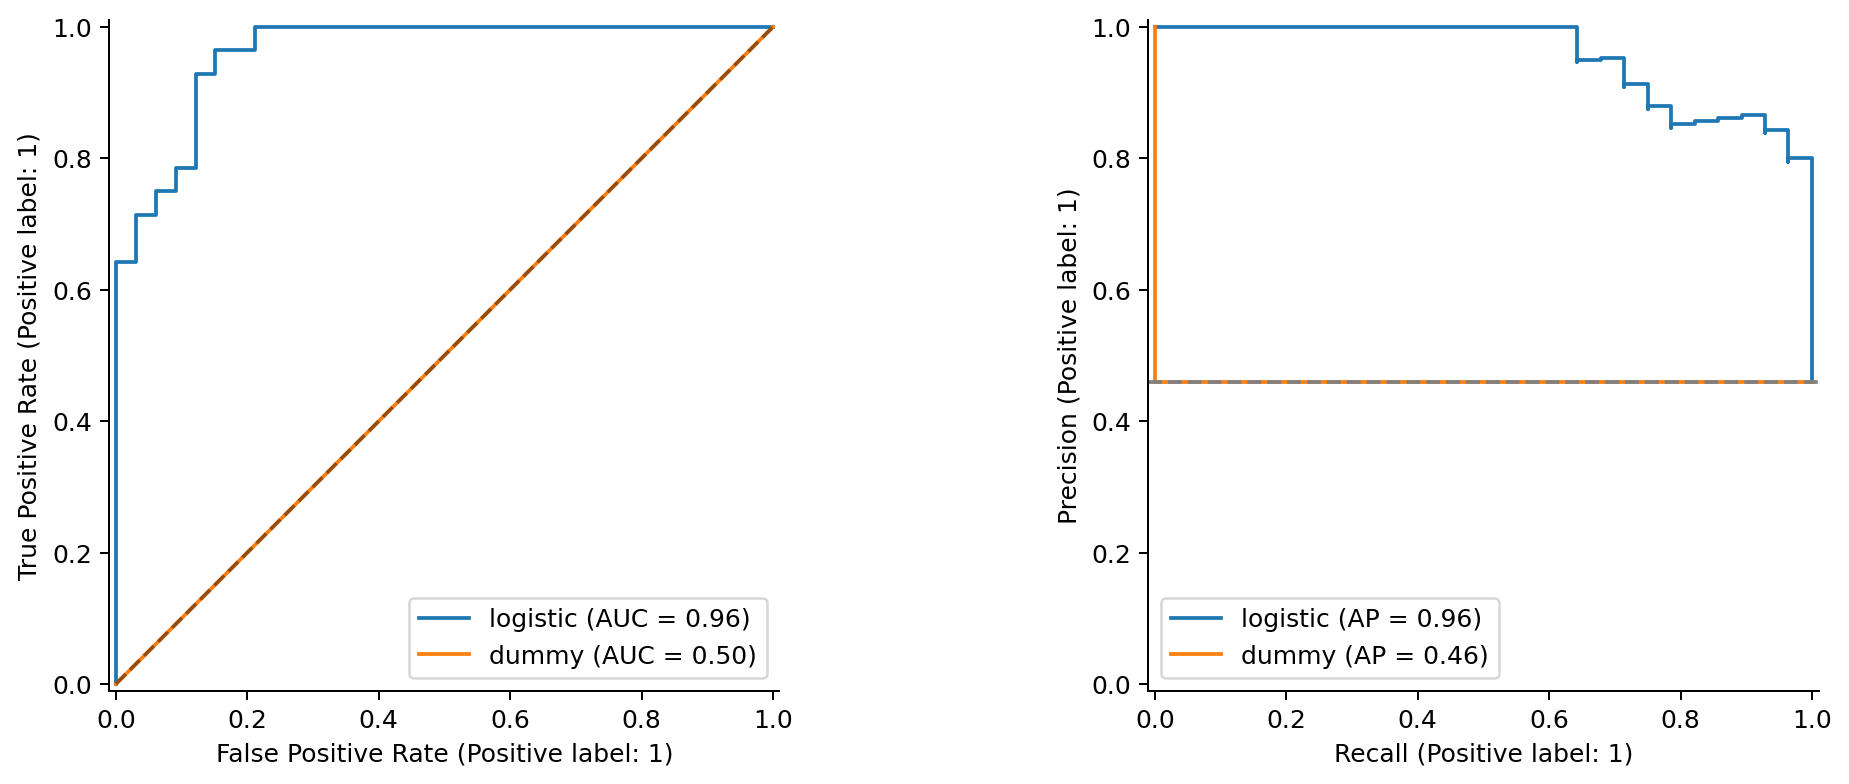

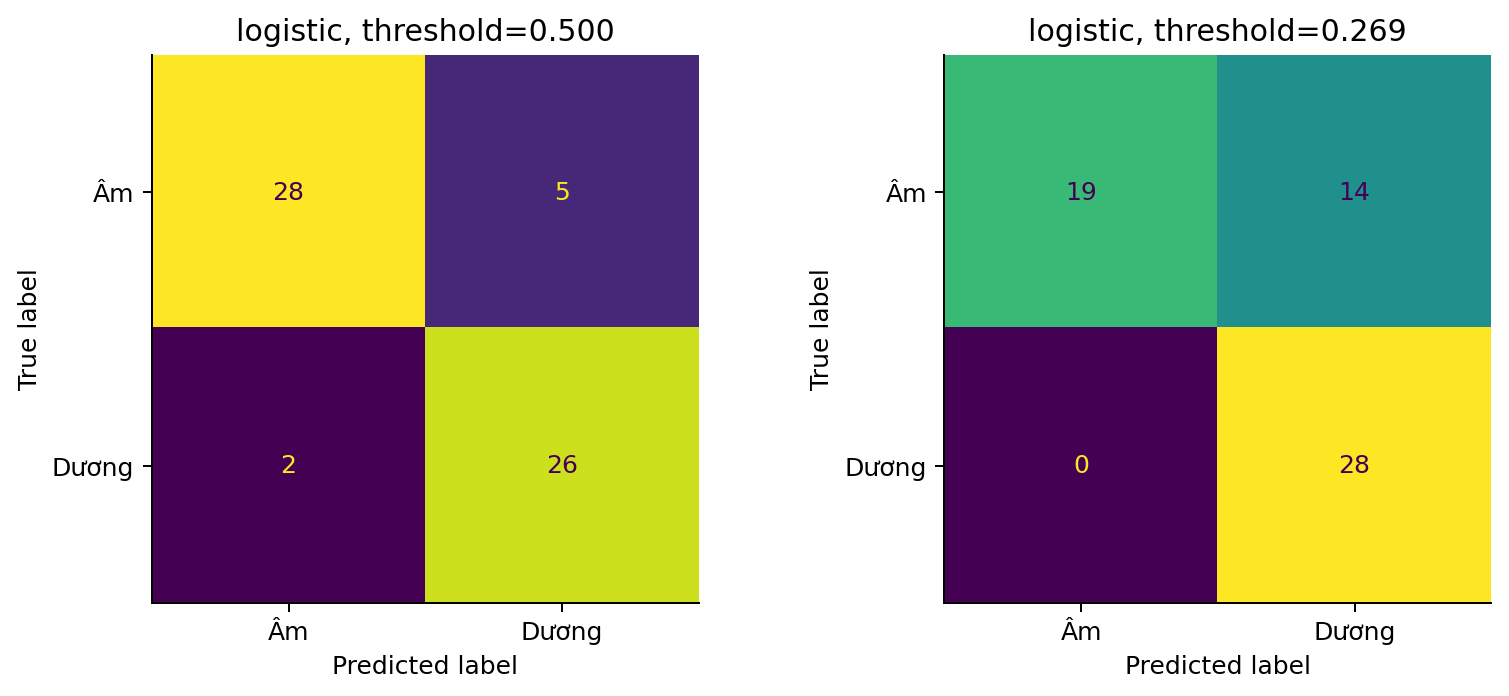

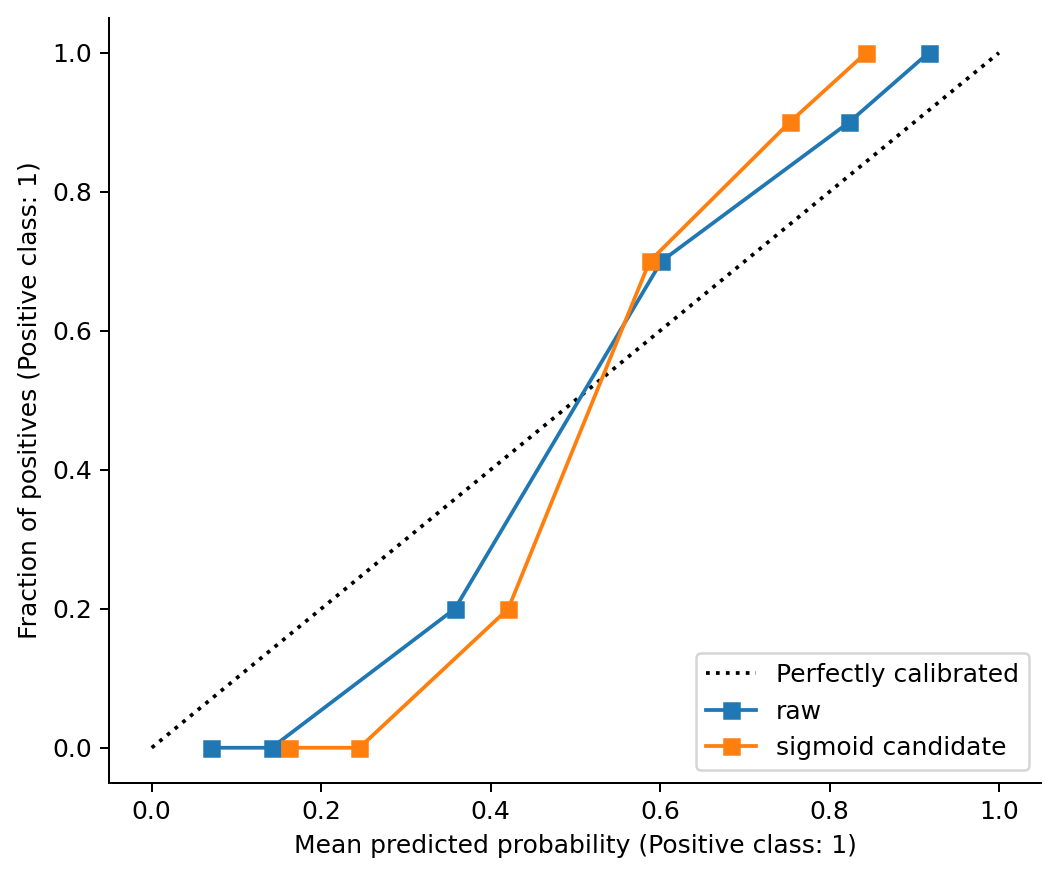

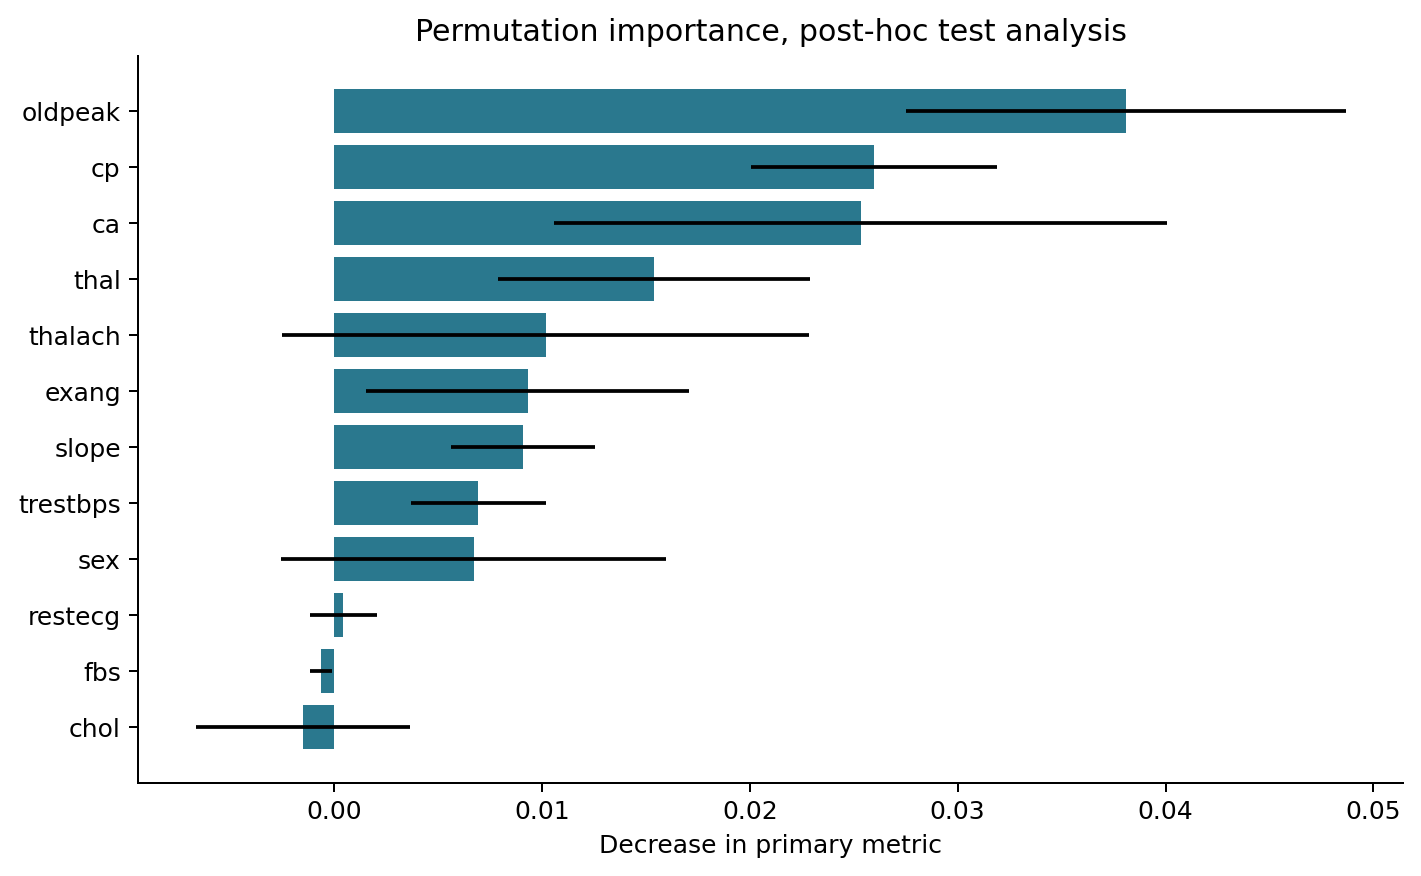

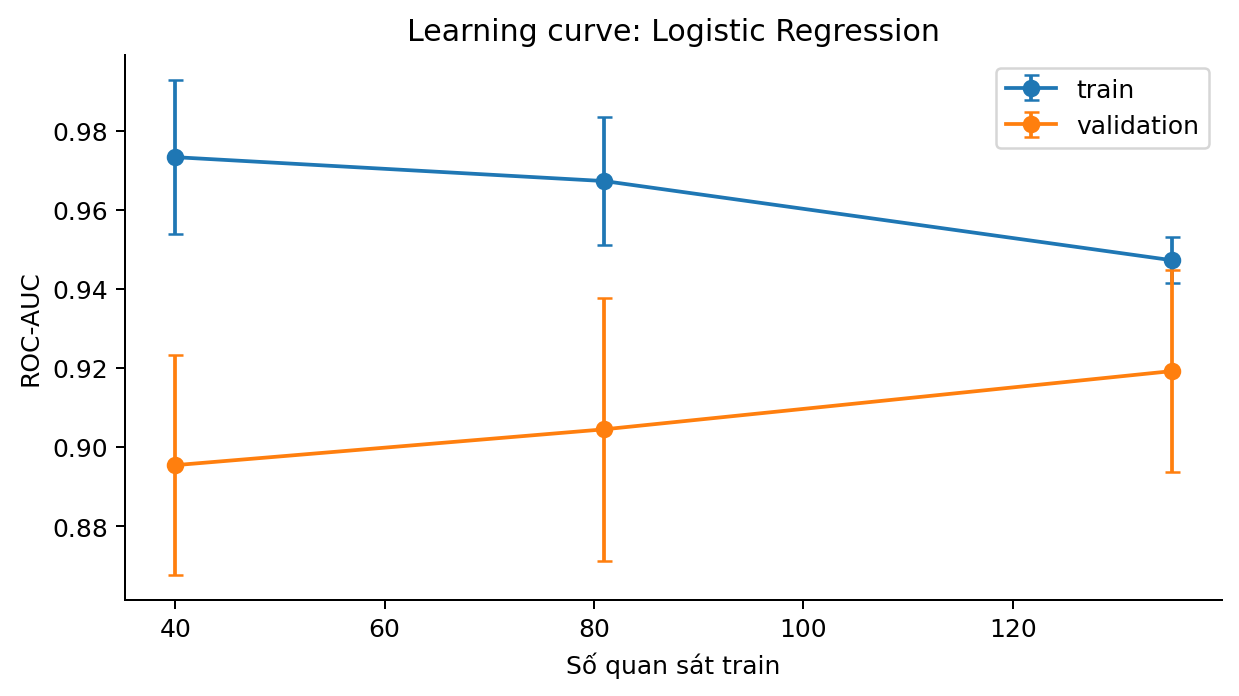

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y,row_id,patient_nbr,probability,prediction,error_type,confidence
0,66.0,1.0,4.0,160.0,228.0,0.0,2.0,138.0,0.0,2.3,1.0,0.0,6.0,0,271,271,0.682421,1,FP,0.682421
1,69.0,1.0,1.0,160.0,234.0,1.0,2.0,131.0,0.0,0.1,2.0,1.0,3.0,0,196,196,0.633583,1,FP,0.633583
2,60.0,1.0,4.0,125.0,258.0,0.0,2.0,141.0,1.0,2.8,2.0,1.0,7.0,1,76,76,0.887750,1,TP,0.887750
3,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0,302,302,0.114159,0,TN,0.885841


,feature,group,n,positive,negative,interpretable,roc_auc,ap,recall,specificity,...,f1,f2,log_loss,threshold,tn,fp,fn,tp,prevalence,alert_rate
0,age_group,<45,13,3,10,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,age_group,45–59,30,14,16,True,0.995536,0.995238,1.0,0.500000,...,0.777778,0.897436,0.349469,0.269344,8.0,8.0,0.0,14.0,0.466667,0.733333
2,age_group,60+,18,11,7,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,sex,0.0,20,7,13,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,sex,1.0,41,21,20,True,0.942857,0.946472,1.0,0.450000,...,0.792453,0.905172,0.398931,0.269344,9.0,11.0,0.0,21.0,0.512195,0.780488
5,cp,1.0,4,1,3,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,cp,2.0,8,2,6,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,cp,3.0,22,3,19,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,cp,4.0,27,22,5,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,missing_group,complete,57,28,29,True,0.958128,0.957158,1.0,0.551724,...,0.811594,0.915033,0.374584,0.269344,16.0,13.0,0.0,28.0,0.491228,0.719298


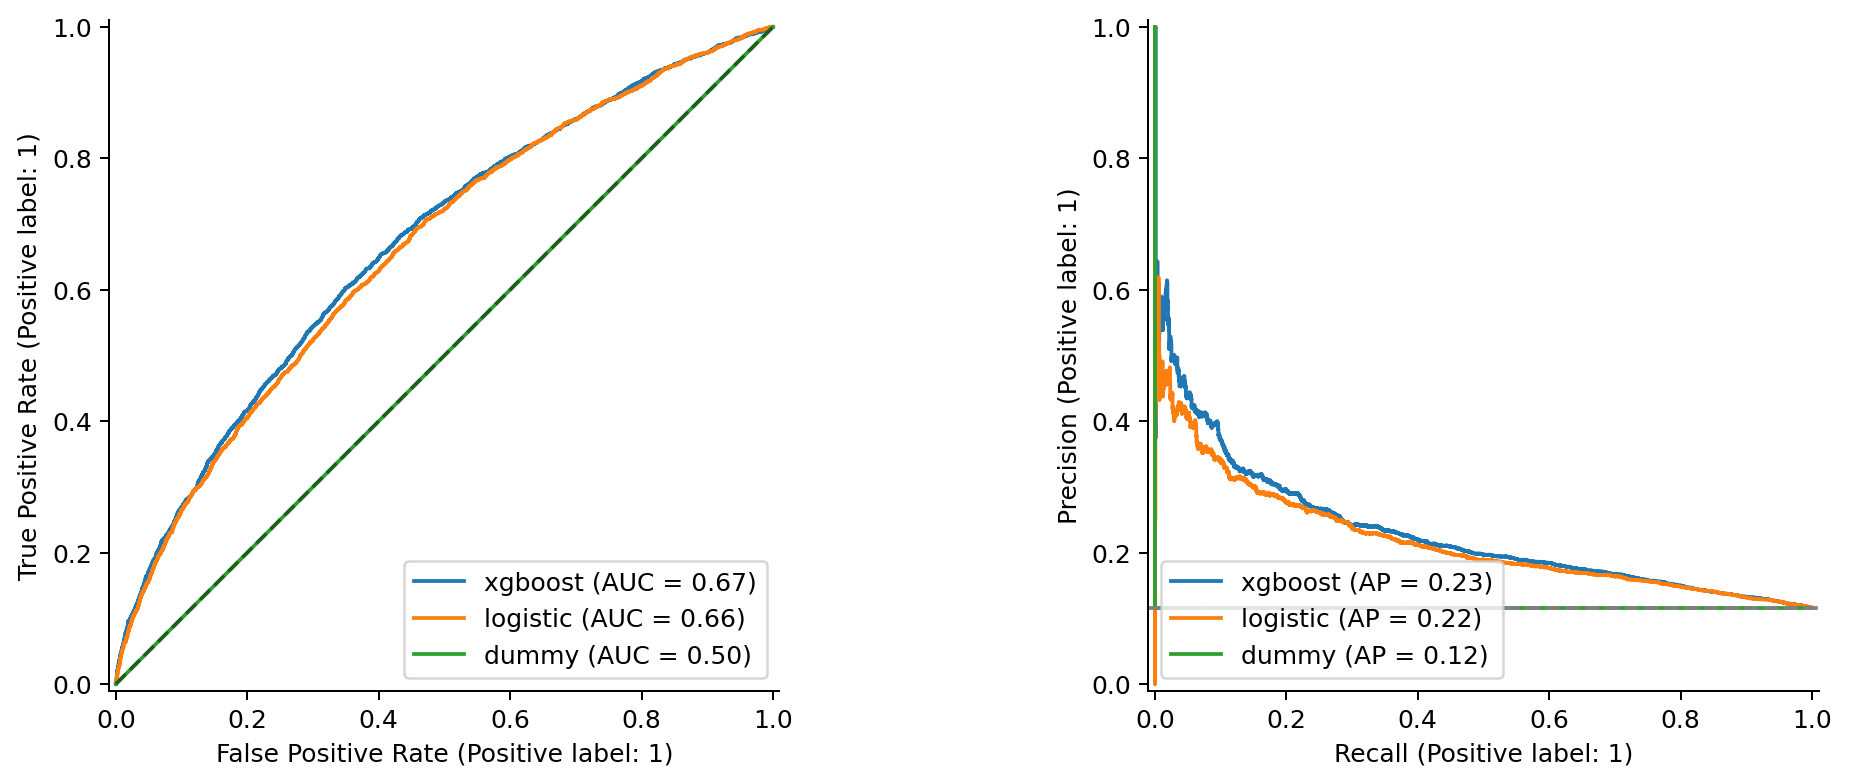

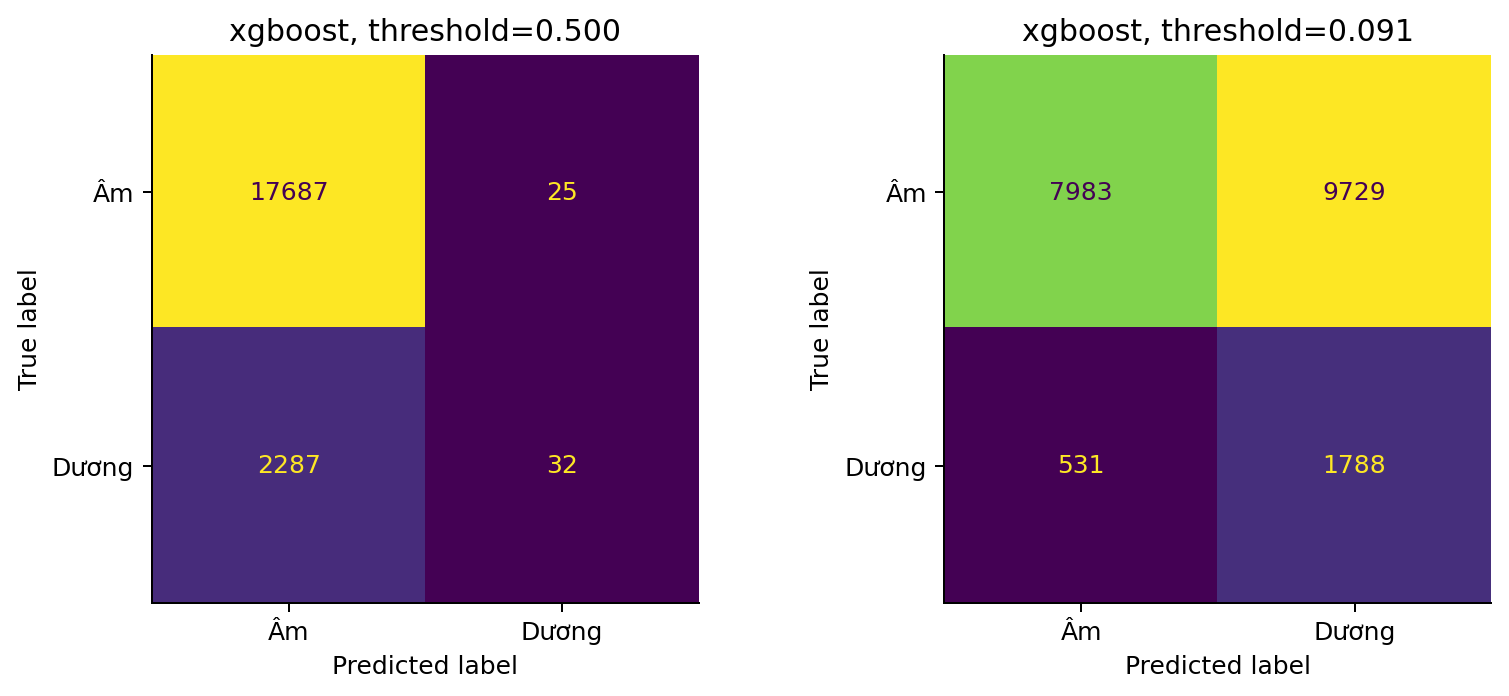

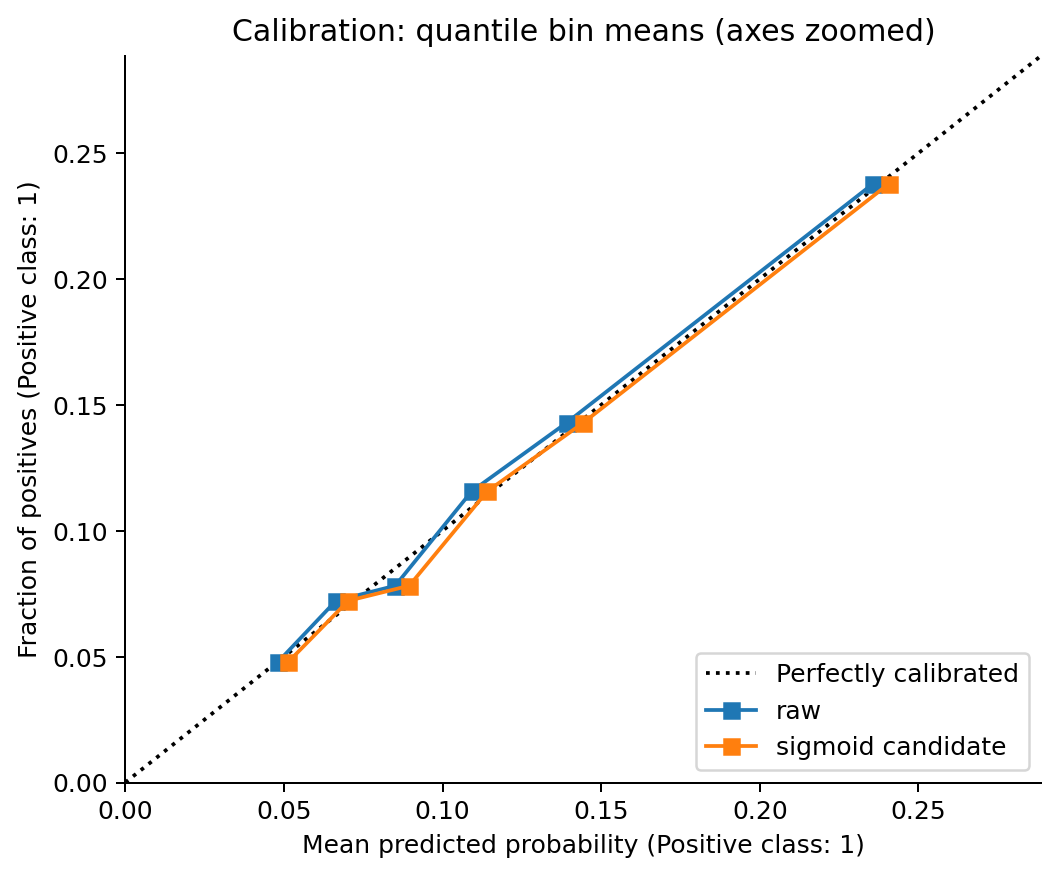

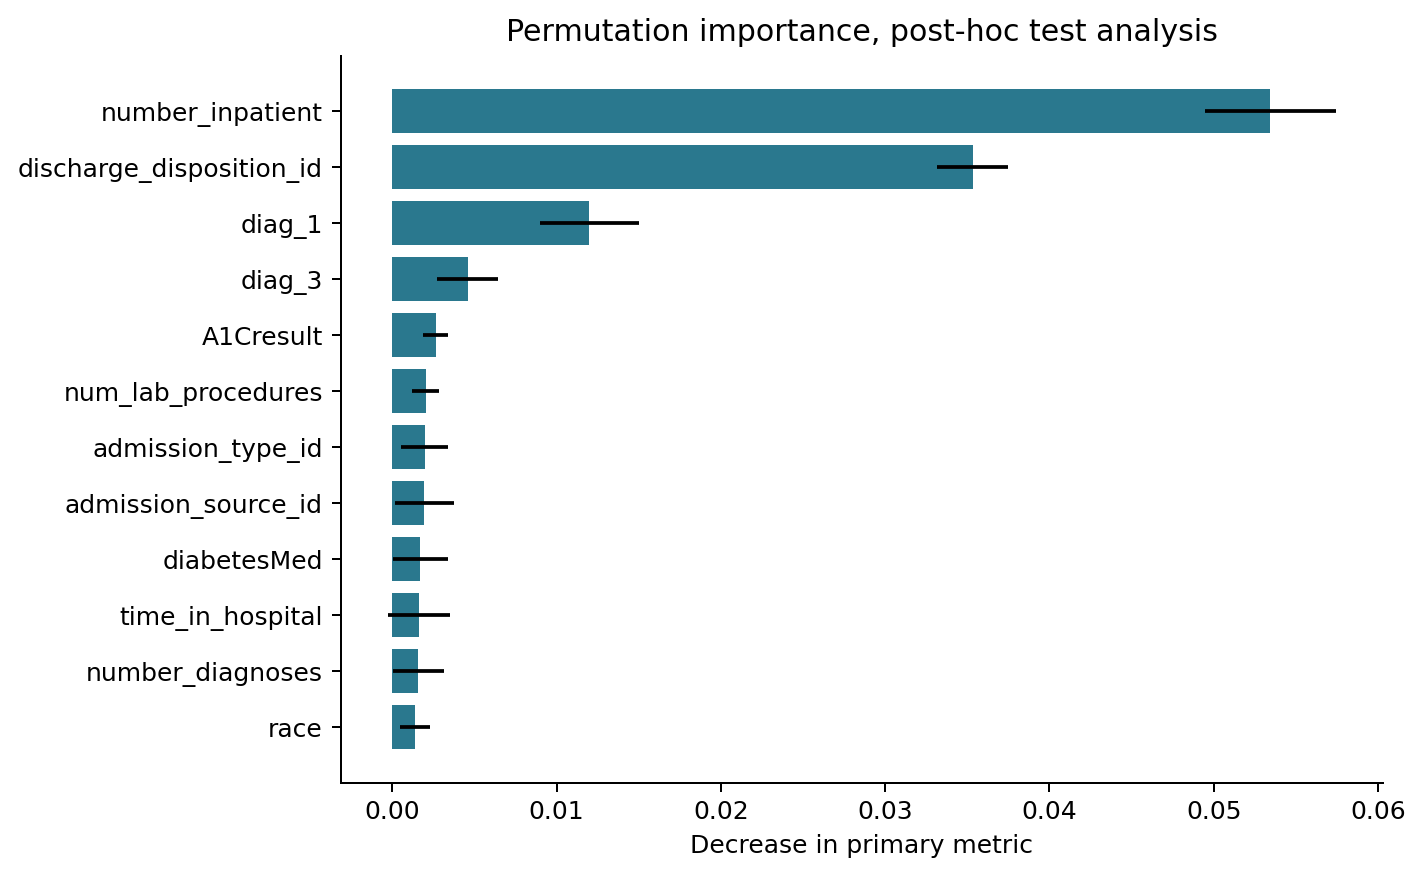

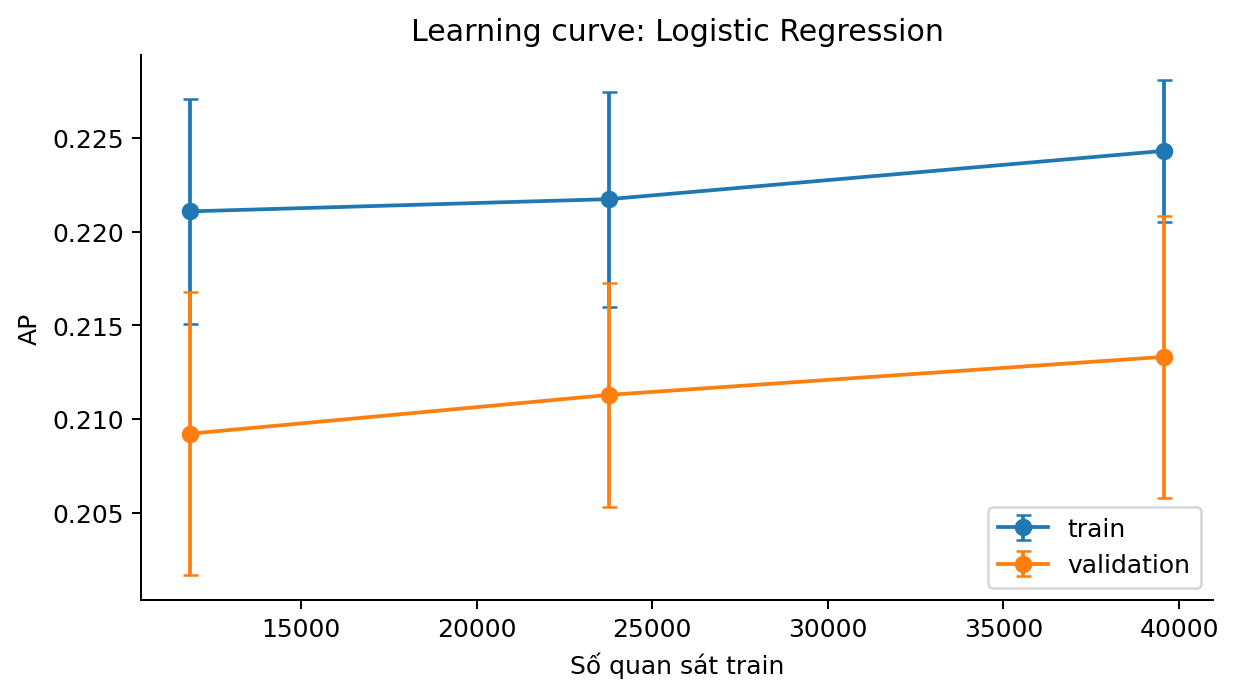

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,y,row_id,probability,prediction,error_type,confidence
0,142665348,60312411,Caucasian,Male,[50-60),NaN,5,1,1,2,...,No,No,Ch,Yes,1,142665348,0.030929,0,FN,0.969071
1,176178870,55167390,Caucasian,Male,[40-50),NaN,1,1,7,2,...,No,No,No,No,1,176178870,0.033856,0,FN,0.966144
2,277605918,90489195,Caucasian,Female,[30-40),NaN,1,1,7,1,...,No,No,Ch,Yes,0,277605918,0.739992,1,FP,0.739992
3,291808098,88785891,Caucasian,Female,[20-30),NaN,1,5,7,6,...,No,No,Ch,Yes,0,291808098,0.690657,1,FP,0.690657
4,309563132,88785891,Caucasian,Female,[20-30),NaN,1,1,7,3,...,No,No,Ch,Yes,1,309563132,0.754566,1,TP,0.754566
5,47228298,14148693,Caucasian,Male,[30-40),NaN,3,1,1,1,...,No,No,No,No,0,47228298,0.023719,0,TN,0.976281


,feature,group,n,positive,negative,interpretable,roc_auc,ap,recall,specificity,...,f1,f2,log_loss,threshold,tn,fp,fn,tp,prevalence,alert_rate
0,age,[0-10),29,1,28,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,age,[10-20),125,11,114,True,0.586922,0.116077,0.090909,0.859649,...,0.071429,0.081967,0.312895,0.09054,98.0,16.0,10.0,1.0,0.088000,0.136000
2,age,[20-30),378,72,306,True,0.757716,0.397910,0.819444,0.575163,...,0.452107,0.618449,0.430074,0.09054,176.0,130.0,13.0,59.0,0.190476,0.500000
3,age,[30-40),729,86,643,True,0.749150,0.308081,0.779070,0.612753,...,0.333333,0.507576,0.322613,0.09054,394.0,249.0,19.0,67.0,0.117970,0.433471
4,age,[40-50),1838,208,1630,True,0.704743,0.297711,0.711538,0.590184,...,0.289062,0.449029,0.320760,0.09054,962.0,668.0,60.0,148.0,0.113166,0.443961
5,age,[50-60),3513,331,3182,True,0.701500,0.211940,0.712991,0.580453,...,0.248160,0.407599,0.290468,0.09054,1847.0,1335.0,95.0,236.0,0.094221,0.447196
6,age,[60-70),4451,513,3938,True,0.664101,0.224652,0.744639,0.468512,...,0.255689,0.421913,0.338569,0.09054,1845.0,2093.0,131.0,382.0,0.115255,0.556055
7,age,[70-80),5015,598,4417,True,0.655222,0.224109,0.809365,0.371972,...,0.251037,0.428319,0.348113,0.09054,1643.0,2774.0,114.0,484.0,0.119242,0.649651
8,age,[80-90),3401,406,2995,True,0.606897,0.190833,0.839901,0.288147,...,0.236888,0.416158,0.357696,0.09054,863.0,2132.0,65.0,341.0,0.119377,0.727139
9,age,[90-100),552,93,459,True,0.560499,0.239794,0.752688,0.283224,...,0.284553,0.453956,0.458226,0.09054,130.0,329.0,23.0,70.0,0.168478,0.722826


In [3]:
for name in ["heart", "readmission"]:
    for suffix in ["roc_pr", "confusion", "calibration", "importance", "learning_curve"]:
        display(Image(filename=str(root/f"artifacts/figures/{name}_{suffix}.png")))
    display(pd.read_csv(root/f"artifacts/metrics/{name}_case_studies.csv"))
    display(pd.read_csv(root/f"artifacts/metrics/{name}_subgroups.csv"))

## Hướng mở rộng
Split conformal trên Heart; coverage biên cần exchangeability, không bảo đảm cho từng bệnh nhân. TabPFN được khảo sát trong literature review, không có số thực nghiệm nếu không chạy.

In [4]:
import json
display(json.loads((root/"artifacts/metrics/heart_conformal.json").read_text(encoding="utf-8")))
display(pd.read_csv(root/"artifacts/metrics/readmission_topk.csv"))

{'results': [{'alpha': 0.05,
   'qhat': 0.9374711113785255,
   'coverage': 1.0,
   'mean_set_size': 1.8852459016393444,
   'singleton_rate': 0.11475409836065574,
   'ambiguous_rate': 0.8852459016393442,
   'empty_rate': 0.0,
   'calibration_n': 36,
   'test_n': 61,
   'method': 'split conformal, score=1-p_true, finite-sample rank'},
  {'alpha': 0.1,
   'qhat': 0.8713208987979245,
   'coverage': 1.0,
   'mean_set_size': 1.540983606557377,
   'singleton_rate': 0.45901639344262296,
   'ambiguous_rate': 0.5409836065573771,
   'empty_rate': 0.0,
   'calibration_n': 36,
   'test_n': 61,
   'method': 'split conformal, score=1-p_true, finite-sample rank'}],
 'exchangeability_assumption': 'Cleveland rows assumed independent; no patient grouping metadata to verify',
 'model': 'Logistic Regression raw, trained on fit only',
 'calibration_ids_hash': 'f06680bfe03dab2b9f5b958d4985b3cbcc457aa3479e2bb576e17f40c47cfbf8'}

,fraction,k,positive_found,precision_at_k,recall_at_k
0,0.05,1002,321,0.320359,0.138422
1,0.10,2004,546,0.272455,0.235446
2,0.20,4007,899,0.224357,0.387667
